In [1]:
import torch

print("Cuda available:",torch.cuda.is_available())

if torch.cuda.is_available():
  print("GPU:",torch.cuda.get_device_name(0))

Cuda available: True
GPU: Tesla T4


In [2]:
import pandas as pd
import numpy as np
import os
from PIL import Image

In [3]:
from google.colab import files
uploaded=files.upload()

Saving archive (1).zip to archive (1).zip


In [4]:
import zipfile

zip_path="/content/archive (1).zip"
extract_path="/content/dog_cat"

with zipfile.ZipFile(zip_path,"r") as zip_ref:
  zip_ref.extractall(extract_path)

print("Extraction Complete|")

Extraction Complete|


In [5]:
import os
print(os.listdir("/content/dog_cat"))

['train', 'test']


In [6]:
from torchvision import datasets, transforms

# Define the image transforms
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder(
    "/content/dog_cat/train",
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    "/content/dog_cat/test",
    transform=test_transform
)

print("Classes:", train_dataset.classes)
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

Classes: ['cats', 'dogs']
Training images: 557
Testing images: 140


In [7]:
!pip install matplotlib

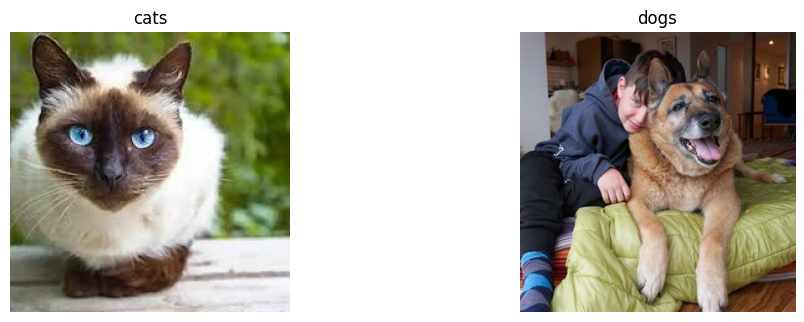

In [8]:
import os
from PIL import Image
import matplotlib.pyplot as plt
dataset_path="/content/dog_cat/test"
classes=os.listdir(dataset_path)
plt.figure(figsize=(12,8))

for i , class_name in enumerate(classes):
    class_path=os.path.join(dataset_path,class_name)
    image_name=os.listdir(class_path)[0]
    image_path=os.path.join(class_path,image_name)
    image=Image.open(image_path)

    plt.subplot(2,2,i+1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")
plt.show()




In [9]:
from PIL import Image
import os

dataset_path="/content/dog_cat/train"

class_name="dogs"
class_path=os.path.join(dataset_path,class_name)

image_name=os.listdir(class_path)[0]
image_path=os.path.join(class_path,image_name)

image=Image.open(image_path)
print("Image Size:",image.size)
print("Image Mode:",image.mode)

Image Size: (228, 221)
Image Mode: RGB


Convert Image to tensor

In [10]:
import torch
from torchvision import transforms
from PIL import Image
import os


dataset_path="/content/dog_cat/train"

class_name="dogs"
class_path=os.path.join(dataset_path,class_name)

image_name=os.listdir(class_path)[0]
image_path=os.path.join(class_path,image_name)

image=Image.open(image_path)

transform=transforms.ToTensor()

image_tensor=transform(image)

print("Original image size:",image.size)
print("Tensor shape",image_tensor.shape)
print("Tensor Data Type",image_tensor.dtype)





Original image size: (228, 221)
Tensor shape torch.Size([3, 221, 228])
Tensor Data Type torch.float32


In [11]:
from torchvision import datasets,transforms

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

dataset=datasets.ImageFolder(
    root="/content/dog_cat/train",
    transform=transform
)
print("Total Image",len(dataset))
print("Classes",dataset.classes)
print("Classes to index",dataset.class_to_idx)

Total Image 557
Classes ['cats', 'dogs']
Classes to index {'cats': 0, 'dogs': 1}


In [12]:
image,label=dataset[0]

print("Image Shape",image.shape)
print("Label",label)
print("Classes",dataset.classes[label])

Image Shape torch.Size([3, 224, 224])
Label 0
Classes cats


In [13]:
from torch.utils.data import DataLoader
train_loader=DataLoader(
    dataset,
    batch_size=32,
    shuffle=True
)
print("Number of Batches",len(train_loader))

Number of Batches 18


In [14]:
image,labels=next(iter(train_loader))

print("Image Shape",image.shape)
print("Label Shape",labels.shape)
print("Labels",labels)

Image Shape torch.Size([32, 3, 224, 224])
Label Shape torch.Size([32])
Labels tensor([0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0,
        1, 0, 1, 1, 1, 0, 1, 0])


In [42]:

from torchvision import datasets, transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

train_dataset = datasets.ImageFolder(
    "/content/dog_cat/train",
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    "/content/dog_cat/test",
    transform=test_transform
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

print("Train classes:", train_dataset.class_to_idx)
print("Test classes:", test_dataset.class_to_idx)



Training images: 557
Testing images: 140
Train classes: {'cats': 0, 'dogs': 1}
Test classes: {'cats': 0, 'dogs': 1}


In [43]:
from torch.utils.data import random_split

total_size=len(train_dataset)
train_size=int(0.85*total_size)
val_size=total_size-train_size

train_dataset,val_dataset=random_split(
    train_dataset,
    [train_size,val_size],
    generator=torch.Generator().manual_seed(42)
)
print("Train:",len(train_dataset))
print("Validation:",len(val_dataset))
print("Test:",len(test_dataset))



Train: 473
Validation: 84
Test: 140


In [44]:
from torch.utils.data import DataLoader

train_loader=DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader=DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)
test_loader=DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)



In [45]:
image,label=next(iter(train_loader))

print("Train Images:",image.shape)
print("Train Labels:",labels.shape)

Train Images: torch.Size([32, 3, 224, 224])
Train Labels: torch.Size([12])


In [46]:
print("Train Batches:",len(train_loader))
print("Validation Batch:",len(val_loader))
print("Test Batches:",len(test_loader))

Train Batches: 15
Validation Batch: 3
Test Batches: 5


Training Pipeline

In [48]:
import torch.nn as nn

class CNNModel(nn.Module):
  def __init__(self):
    super().__init__()

    self.features = nn.Sequential(
        nn.Conv2d(3, 32, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),

        nn.Conv2d(32, 64, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),

        nn.AdaptiveAvgPool2d((7, 7))
    )

    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(64 * 7 * 7, 128),
        nn.ReLU(),
        nn.Linear(128, 2)
    )

  def forward(self, x):
    x = self.features(x)
    x = self.classifier(x)
    return x

In [50]:
import torch.nn as nn

class CNNModel(nn.Module):
  def __init__(self):
    super().__init__()

    self.features = nn.Sequential(
        nn.Conv2d(3, 32, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),

        nn.Conv2d(32, 64, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),

        nn.AdaptiveAvgPool2d((7, 7))
    )

    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(64 * 7 * 7, 128),
        nn.ReLU(),
        nn.Linear(128, 2)
    )

  def forward(self, x):
    x = self.features(x)
    x = self.classifier(x)
    return x

model=CNNModel()

image,labels=next(iter(train_loader))

output=model(image)

print("Output Shape:",output.shape)

Output Shape: torch.Size([32, 2])


CNN FORWARD PASS

In [51]:
model = CNNModel()
images,labels=next(iter(train_loader))

outputs=model(images)

print("input shape",images.shape)
print("Output shape",outputs.shape)

predicted=outputs.argmax(dim=1)

print("Predicted:",predicted)
print("Actual:",labels)

input shape torch.Size([32, 3, 224, 224])
Output shape torch.Size([32, 2])
Predicted: tensor([1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1,
        1, 1, 0, 0, 0, 1, 0, 1])
Actual: tensor([0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1,
        0, 0, 0, 0, 0, 0, 0, 0])


CNN TRAIN

In [52]:
criterion=nn.CrossEntropyLoss()

images,labels=next(iter(train_loader))

outputs=model(images)

loss=criterion(outputs,labels)

print("Loss:",loss.item())

Loss: 0.6925851702690125


OPtimizer

In [53]:
optimizer=torch.optim.Adam(model.parameters(),
                           lr=0.001
                           )
print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


Learning Step

In [54]:
images,labels=next(iter(train_loader))

optimizer.zero_grad()

outputs=model(images)

loss=criterion(outputs,labels)

loss.backward()

optimizer.step()

print("Loss:",loss.item())

Loss: 0.6936790347099304


In [55]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cuda


In [56]:
num_epochs=10

model.to(device)
optimizer=torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

for epoch in range(num_epochs):
  model.train()

  total_loss=0
  correct=0
  total=0

  for images,labels in train_loader:

    images=images.to(device)
    labels=labels.to(device)

    optimizer.zero_grad()

    outputs=model(images)

    loss=criterion(outputs,labels)
    loss.backward()
    optimizer.step()

    total_loss+=loss.item()

    predicted=outputs.argmax(dim=1)

    total+=labels.size(0)
    correct+=(predicted==labels).sum().item()

average_loss=total_loss/len(train_loader)
accuracy=100*correct/total

print(
    f"Epoch [{epoch+1}/{num_epochs}]"
    f"Loss:{average_loss:.4f}"
    f"Accuracy:{accuracy:.2f}%"
)


Epoch [10/10]Loss:0.5425Accuracy:70.40%


In [57]:
model.eval()

CNNModel(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): AdaptiveAvgPool2d(output_size=(7, 7))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=2, bias=True)
  )
)

In [62]:
model.eval()
val_loss=0
correct=0
total=0

with torch.no_grad():
  for images,labels in val_loader:
    images=images.to(device)
    labels=labels.to(device)

    outputs=model(images)

    loss=criterion(outputs,labels)

    val_loss+=loss.item()

    predicted=outputs.argmax(dim=1)

    total+=labels.size(0)

    correct+=(predicted==labels).sum().item()

  average_loss=val_loss/len(val_loader)
  val_accuracy=100*correct/total

print(f"Validation Loss:{average_loss:.4f}")
print(f"Validation Accuracy:{val_accuracy:.4f}")


Validation Loss:0.7439
Validation Accuracy:61.9048


In [59]:
model.eval()

correct=0
total=0

with torch.no_grad():
  for images,labels in test_loader:
    images=images.to(device)
    labels=labels.to(device)

    outputs=model(images)
    predicted=outputs.argmax(dim=1)

    total+=labels.size(0)

    correct+=(predicted==labels).sum().item()

test_accuracy=100*correct/total
print(f"Test Accuracy:{test_accuracy:.2f}%")

Test Accuracy:67.86%


Confusion Matrix

In [60]:
from sklearn.metrics import confusion_matrix

import numpy as np

model.eval()

all_labels=[]
all_predictions=[]

with torch.no_grad():

  for images,labels in test_loader:

    images=images.to(device)
    labels=labels.to(device)

    outputs=model(images)

    predictions=outputs.argmax(dim=1)

    all_labels.extend(labels.cpu().numpy())
    all_predictions.extend(predictions.cpu().numpy())

all_labels=np.array(all_labels)
all_predictions=np.array(all_predictions)

print("Actual Labels",all_labels)
print("predicted labels:",all_predictions.shape)


Actual Labels [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
predicted labels: (140,)


In [61]:
#confusion metrix

cm=confusion_matrix(
    all_labels,
    all_predictions
)

print(cm)
print(dataset.classes)

[[40 30]
 [15 55]]
['cats', 'dogs']


Text(0.5, 1.0, 'Confussion Metrix-Cat and Dog Clasification')

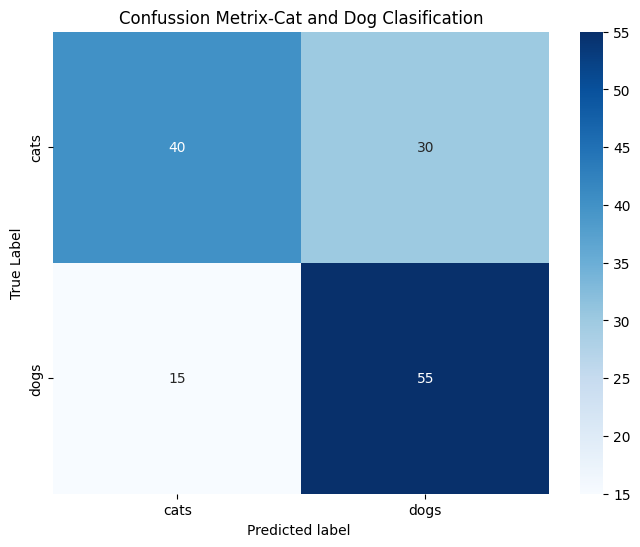

In [63]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=dataset.classes,
    yticklabels=dataset.classes
)
plt.xlabel("Predicted label ")
plt.ylabel("True Label")

plt.title("Confussion Metrix-Cat and Dog Clasification")

Classification Report

In [64]:
from sklearn.metrics import classification_report

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=dataset.classes
        )
)

              precision    recall  f1-score   support

        cats       0.73      0.57      0.64        70
        dogs       0.65      0.79      0.71        70

    accuracy                           0.68       140
   macro avg       0.69      0.68      0.67       140
weighted avg       0.69      0.68      0.67       140



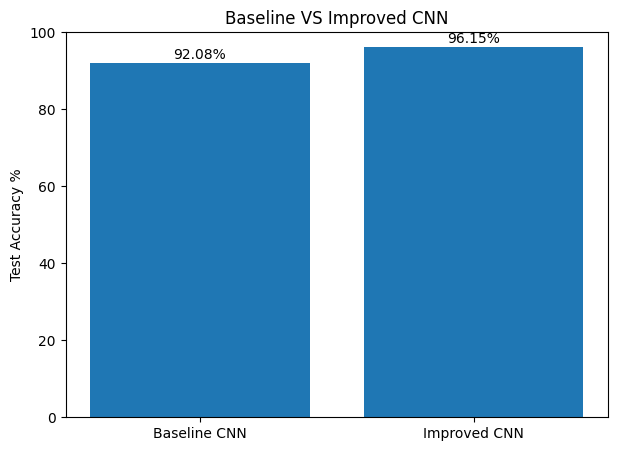

In [66]:
import matplotlib.pyplot as plt

models=["Baseline CNN","Improved CNN"]
accuracies=[92.08,96.15]

plt.figure(figsize=(7,5))

plt.bar(models,accuracies)

plt.ylabel("Test Accuracy %")
plt.title("Baseline VS Improved CNN")

plt.ylim(0,100)

for i,value in enumerate(accuracies):
  plt.text(i,value+1,f"{value:.2f}%",ha="center")

plt.show()


In [ ]:
model = CNNModel().to(device)

model.load_state_dict(
    torch.load(
        "/content/cat_",
        map_location=device
    )
)

model.eval()

print("Model loaded successfully!")

In [78]:
from PIL import Image
import torch
import os
from torchvision import transforms

# Using an existing cat image from your extracted test folder
test_cats_dir = "/content/dog_cat/test/cats"
cat_images = os.listdir(test_cats_dir)
image_path = os.path.join(test_cats_dir, cat_images[0])

image = Image.open(image_path).convert("RGB")

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

image = transform(image)
image = image.unsqueeze(0)

model.eval()

with torch.no_grad():
    image = image.to(device)
    output = model(image)
    predicted = output.argmax(dim=1).item()

classes = ["cats", "dogs"]

print("Evaluating image:", image_path)
print("Prediction:", classes[predicted])

Evaluating image: /content/dog_cat/test/cats/cat_290.jpg
Prediction: dogs


In [80]:
from google.colab import files

uploaded = files.upload()

Saving dog_9.jpg to dog_9.jpg


In [82]:
from PIL import Image
import torch
from torchvision import transforms

image_path = next(iter(uploaded))

image = Image.open(image_path).convert("RGB")

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

image_tensor = transform(image)
image_tensor = image_tensor.unsqueeze(0)

model.eval()

with torch.no_grad():
    image_tensor = image_tensor.to(device)
    output = model(image_tensor)
    predicted = output.argmax(dim=1).item()

# Using test_dataset.classes since train_dataset is a Subset object
classes = test_dataset.classes

print("Predicted Class:", classes[predicted])

Predicted Class: dogs
